# 🕷️ Who's Under the Mask? Telling Three Spider-Men Apart

CSCI1409 Deep Learning – Bonus Project (KBTU, Fall 2026). One student, three Spider-Man actors, one tiny YOLO model.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Ayamourr/spiderman-actor-detector/blob/main/spiderman_detector.ipynb)

**The three classes:** `Andrew-Garfield`, `Tobey Maguire`, `Tom Holland`

**How to run it (about 10 minutes):**
1. Click **Runtime → Change runtime type → T4 GPU → Save**
2. Click **Runtime → Run all**

**What happens, in order:**
1. Install tools (exact versions) and download the data
2. Clean the data: hunt for near-duplicate photos that sit in different splits (that would be cheating by accident)
3. Count images and boxes, and draw some ground-truth examples
4. Train the baseline (image size 640)
5. Controlled experiment: the same thing but image size 320
6. Test the winner on the test set (only once!)
7. Show predictions, find failure cases, save the evidence

**AI help:** I used Claude (Anthropic's AI assistant) for explanations, code and README drafts. I ran every cell myself. Details are in the README.

In [14]:
!pip -q install ultralytics==8.4.216 gdown==5.2.2 imagehash==4.3.2
import ultralytics, torch
print("ultralytics:", ultralytics.__version__)
print("torch:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

ultralytics: 8.4.216
torch: 2.14.1+cu130
GPU available: True


## Step 1 – Get the data
The data is the Roboflow Universe dataset *actor* (CC BY 4.0), exported in YOLO format and mirrored on Google Drive so this notebook can download it without a login. The zip file contains junk from a Mac (`__MACOSX`), so we skip those files.

In [15]:
import os, zipfile
!rm -rf /content/data /content/actor.zip
!gdown 1S7XdQ38M0z938mVoYKqjtCBmw8R5ej74 -O actor.zip

with zipfile.ZipFile("actor.zip") as z:
    for n in z.namelist():
        if not n.startswith("__MACOSX") and ".DS_Store" not in n:
            z.extract(n, "/content/data")

print(os.listdir("/content/data"), os.listdir("/content/data/actor"))

Downloading...
From: https://drive.google.com/uc?id=1S7XdQ38M0z938mVoYKqjtCBmw8R5ej74
To: /content/actor.zip
100% 7.74M/7.74M [00:00<00:00, 22.7MB/s]
['actor'] ['valid', 'data.yaml', 'README.roboflow.txt', 'test', 'train']


## Step 2 – Clean the data (twin hunt 👯)
If the same photo (or a copy of it) is in both training and validation/test, the model has already "seen the answer" and the score looks better than it really is. This is called **data leakage**.

- **Cell A:** compare whole images with a perceptual hash (pHash, a short fingerprint of a picture). Distance ≤ 8 = near-duplicate.
- **Cell B:** move leaked images into the earlier split (train → valid → test). The fix is saved in `split_fixes.txt`.
- **Cell C:** same idea, but on the **cropped boxes**, to catch photos of the same event taken from other angles (distance ≤ 10). Saved in `crop_split_fixes.txt`.

No random numbers are used here, so the result is always the same.

In [16]:
!pip -q install imagehash==4.3.2
import os, glob, shutil, itertools, collections, random
import cv2, imagehash
import matplotlib.pyplot as plt
from PIL import Image

root = "/content/data/actor"
names = ['Andrew-Garfield', 'Tobey Maguire', 'Tom Holland']
splits = ["train", "valid", "test"]

similar pairs in total: 3
similar pairs across different splits (leakage risk): 1


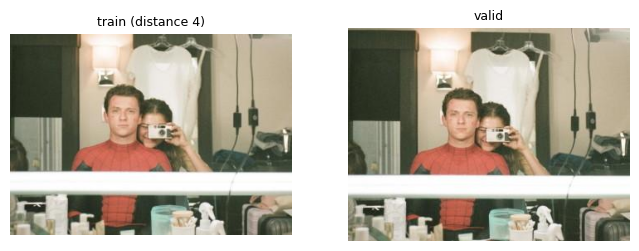

In [17]:
import imagehash, itertools
from PIL import Image

hashes = []
for s in splits:
    for p in sorted(glob.glob(f"{root}/{s}/images/*")):
        hashes.append((s, p, imagehash.phash(Image.open(p).convert("RGB"))))

pairs = []
for (s1, p1, h1), (s2, p2, h2) in itertools.combinations(hashes, 2):
    d = h1 - h2          # 0 = identical, small = very similar
    if d <= 8:
        pairs.append((d, s1, s2, p1, p2))
pairs.sort(key=lambda x: x[0])

cross = [x for x in pairs if x[1] != x[2]]
print("similar pairs in total:", len(pairs))
print("similar pairs across different splits (leakage risk):", len(cross))

show = cross[:4]
if show:
    fig, axes = plt.subplots(len(show), 2, figsize=(8, 4 * len(show)))
    axes = axes.reshape(len(show), 2)
    for row, (d, s1, s2, p1, p2) in zip(axes, show):
        row[0].imshow(Image.open(p1)); row[0].set_title(f"{s1} (distance {d})", fontsize=9)
        row[1].imshow(Image.open(p2)); row[1].set_title(s2, fontsize=9)
        row[0].axis("off"); row[1].axis("off")
    plt.show()

In [18]:
import os, shutil

order = {"train": 0, "valid": 1, "test": 2}
moved = []
for d, s1, s2, p1, p2 in cross:
    # keep the pair together in the "earlier" split (train < valid < test)
    if order[s1] <= order[s2]:
        keep_split, move_split, move_path = s1, s2, p2
    else:
        keep_split, move_split, move_path = s2, s1, p1

    stem = os.path.splitext(os.path.basename(move_path))[0]
    dst_img = f"{root}/{keep_split}/images/{os.path.basename(move_path)}"
    src_lbl = f"{root}/{move_split}/labels/{stem}.txt"
    dst_lbl = f"{root}/{keep_split}/labels/{stem}.txt"

    if os.path.exists(move_path):
        shutil.move(move_path, dst_img)
        if os.path.exists(src_lbl):
            shutil.move(src_lbl, dst_lbl)
        moved.append(f"{os.path.basename(move_path)}: {move_split} -> {keep_split} (hash distance {d})")

with open("split_fixes.txt", "w") as f:
    f.write("\n".join(moved))
print("\n".join(moved))

115_jpg.rf.436d21df4a978d547b029ad4b25aa5ca.jpg: valid -> train (hash distance 4)


In [19]:

import os, glob, shutil, itertools, cv2, imagehash
from PIL import Image

root = "/content/data/actor"
splits = ["train", "valid", "test"]

# 1. Compute pHash on each cropped bounding box across all splits
box_hashes = []
for s in splits:
    for p in sorted(glob.glob(f"{root}/{s}/images/*")):
        stem = os.path.splitext(os.path.basename(p))[0]
        lp = f"{root}/{s}/labels/{stem}.txt"
        if not os.path.exists(lp):
            continue

        img = cv2.imread(p)
        if img is None:
            continue
        h, w = img.shape[:2]

        with open(lp) as f:
            lines = [l.strip().split() for l in f.read().splitlines() if l.strip()]

        for parts in lines:
            if len(parts) != 5:
                continue
            _, cx, cy, bw, bh = parts
            cx, cy, bw, bh = float(cx), float(cy), float(bw), float(bh)
            x1 = max(0, int((cx - bw / 2) * w))
            y1 = max(0, int((cy - bh / 2) * h))
            x2 = min(w, int((cx + bw / 2) * w))
            y2 = min(h, int((cy + bh / 2) * h))

            crop = img[y1:y2, x1:x2]
            if crop.size == 0:
                continue
            pil_crop = Image.fromarray(cv2.cvtColor(crop, cv2.COLOR_BGR2RGB))
            box_hashes.append((s, p, imagehash.phash(pil_crop)))

# 2. Find similar crops across DIFFERENT splits (try 10 first; bump to 12 if needed)
threshold = 10
cross_box = []
for (s1, p1, h1), (s2, p2, h2) in itertools.combinations(box_hashes, 2):
    if s1 == s2 or p1 == p2:
        continue
    d = h1 - h2
    if d <= threshold:
        cross_box.append((d, s1, s2, p1, p2))

cross_box.sort(key=lambda x: x[0])
print("Cross-split similar crop pairs found:", len(cross_box))

# 3. Move leaked image + label into the earlier split (train < valid < test)
order = {"train": 0, "valid": 1, "test": 2}
moved_crops = []
already_moved = set()

for d, s1, s2, p1, p2 in cross_box:
    if p1 in already_moved or p2 in already_moved:
        continue

    if order[s1] <= order[s2]:
        keep_split, move_split, move_path = s1, s2, p2
    else:
        keep_split, move_split, move_path = s2, s1, p1

    fname = os.path.basename(move_path)
    stem = os.path.splitext(fname)[0]
    src_img = f"{root}/{move_split}/images/{fname}"
    dst_img = f"{root}/{keep_split}/images/{fname}"
    src_lbl = f"{root}/{move_split}/labels/{stem}.txt"
    dst_lbl = f"{root}/{keep_split}/labels/{stem}.txt"

    if os.path.exists(src_img):
        shutil.move(src_img, dst_img)
        if os.path.exists(src_lbl):
            shutil.move(src_lbl, dst_lbl)
        already_moved.add(move_path)
        moved_crops.append(f"{fname}: {move_split} -> {keep_split} (crop hash distance {d})")

with open("crop_split_fixes.txt", "w") as f:
    f.write("\n".join(moved_crops))

print("\n".join(moved_crops) if moved_crops else "No files moved.")

Cross-split similar crop pairs found: 4
136_jpg.rf.c29a06c8e50243026ad524dc996c82e7.jpg: valid -> train (crop hash distance 8)
131_jpg.rf.9627b448da8db4575d154c7bdcf44952.jpg: test -> train (crop hash distance 8)
122_jpg.rf.3461b546ddfd42d7b0bf2028f76b9499.jpg: valid -> train (crop hash distance 10)
121_jpg.rf.261b9067a959c36cb798fd85cbb08ea2.jpg: test -> valid (crop hash distance 10)


## Step 3 – Count and look
We count images and boxes per split and per actor, and check for missing, empty or broken label files. Then we draw 6 training images (2 per actor) with their true boxes.

In [20]:
import os, glob, collections
root = "/content/data/actor"
names = ['Andrew-Garfield', 'Tobey Maguire', 'Tom Holland']
splits = ["train", "valid", "test"]

for s in splits:
    print(s, "contains:", os.listdir(f"{root}/{s}"))

print()
for s in splits:
    imgs = sorted(glob.glob(f"{root}/{s}/images/*"))
    boxes = collections.Counter()
    no_label, empty_label, bad_lines = [], [], []
    for p in imgs:
        stem = os.path.splitext(os.path.basename(p))[0]
        lp = f"{root}/{s}/labels/{stem}.txt"
        if not os.path.exists(lp):
            no_label.append(stem)
            continue
        lines = [l.split() for l in open(lp).read().strip().splitlines() if l.strip()]
        if not lines:
            empty_label.append(stem)
        for parts in lines:
            ok = len(parts) == 5 and parts[0] in ("0", "1", "2") and all(0 <= float(v) <= 1 for v in parts[1:])
            if ok:
                boxes[names[int(parts[0])]] += 1
            else:
                bad_lines.append((stem, parts))
    print(f"{s}: {len(imgs)} images, {sum(boxes.values())} boxes")
    for n in names:
        print(f"    {n}: {boxes[n]} boxes")
    print(f"    images without label file: {len(no_label)}")
    print(f"    images with empty label file: {len(empty_label)}")
    print(f"    bad label lines: {len(bad_lines)}")

train contains: ['labels', 'images']
valid contains: ['labels', 'images']
test contains: ['labels', 'images']

train: 282 images, 304 boxes
    Andrew-Garfield: 104 boxes
    Tobey Maguire: 84 boxes
    Tom Holland: 116 boxes
    images without label file: 0
    images with empty label file: 0
    bad label lines: 0
valid: 77 images, 82 boxes
    Andrew-Garfield: 26 boxes
    Tobey Maguire: 29 boxes
    Tom Holland: 27 boxes
    images without label file: 0
    images with empty label file: 0
    bad label lines: 0
test: 38 images, 42 boxes
    Andrew-Garfield: 19 boxes
    Tobey Maguire: 9 boxes
    Tom Holland: 14 boxes
    images without label file: 0
    images with empty label file: 0
    bad label lines: 0


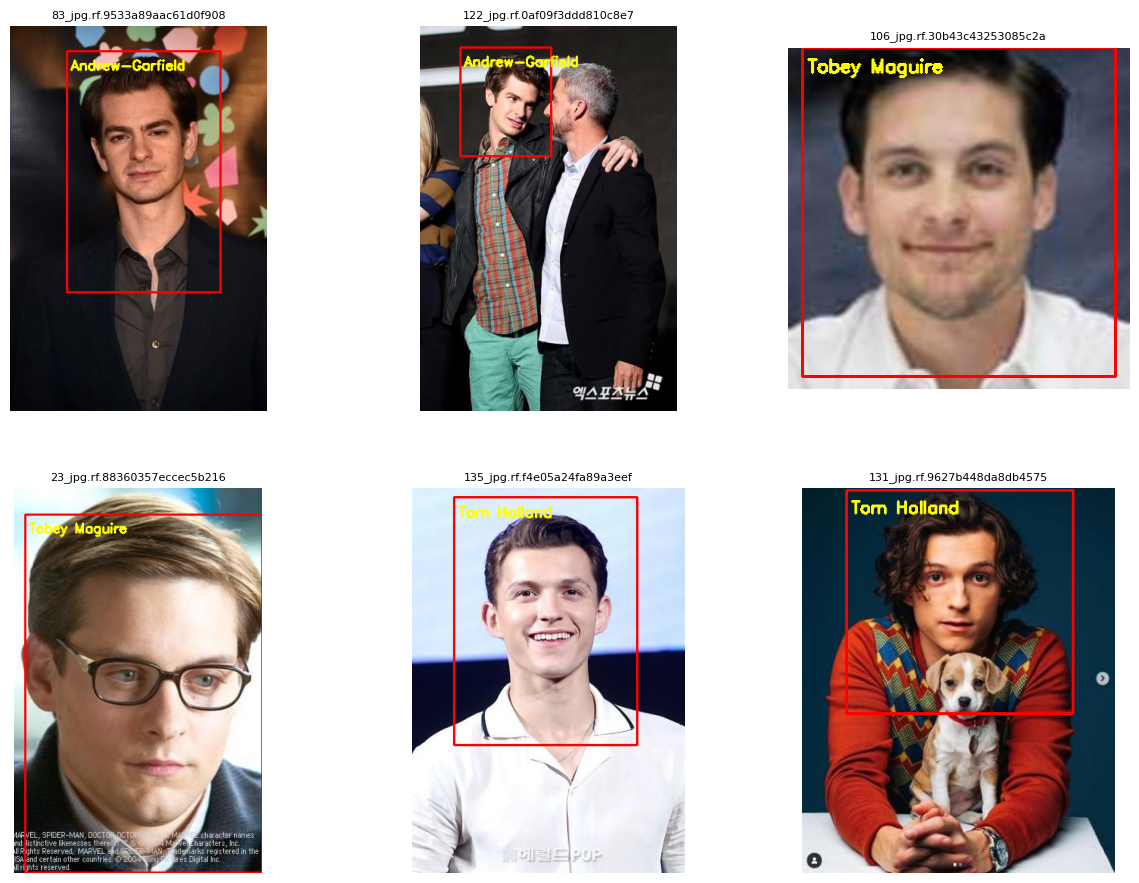

In [21]:
import cv2, random
import matplotlib.pyplot as plt

random.seed(42)

# group train images by the class of their first box
by_class = {0: [], 1: [], 2: []}
for p in sorted(glob.glob(f"{root}/train/images/*")):
    stem = os.path.splitext(os.path.basename(p))[0]
    first = open(f"{root}/train/labels/{stem}.txt").read().split()[0]
    by_class[int(first)].append(p)

sample = []
for c in (0, 1, 2):
    sample += random.sample(by_class[c], 2)

fig, axes = plt.subplots(2, 3, figsize=(15, 11))
for ax, p in zip(axes.flatten(), sample):
    img = cv2.cvtColor(cv2.imread(p), cv2.COLOR_BGR2RGB)
    h, w = img.shape[:2]
    stem = os.path.splitext(os.path.basename(p))[0]
    for line in open(f"{root}/train/labels/{stem}.txt").read().strip().splitlines():
        c, x, y, bw, bh = line.split()[:5]
        c, x, y, bw, bh = int(c), float(x), float(y), float(bw), float(bh)
        x1, y1 = int((x - bw / 2) * w), int((y - bh / 2) * h)
        x2, y2 = int((x + bw / 2) * w), int((y + bh / 2) * h)
        cv2.rectangle(img, (x1, y1), (x2, y2), (255, 0, 0), max(2, w // 120))
        cv2.putText(img, names[c], (x1 + 5, y1 + 25), cv2.FONT_HERSHEY_SIMPLEX,
                    max(0.6, w / 700), (255, 255, 0), 2)
    ax.imshow(img)
    ax.set_title(os.path.basename(p)[:28], fontsize=8)
    ax.axis("off")
plt.savefig("ground_truth_examples.png", bbox_inches="tight", dpi=120)
plt.show()

## Step 4 – Settings
`data.yaml` tells YOLO where the images are and what the 3 classes are called (0 = Andrew-Garfield, 1 = Tobey Maguire, 2 = Tom Holland). We also check how big the photos are.

In [22]:
import glob, numpy as np
from PIL import Image

yaml_text = """path: /content/data/actor
train: train/images
val: valid/images
test: test/images
names:
  0: Andrew-Garfield
  1: Tobey Maguire
  2: Tom Holland
"""
open("/content/data.yaml", "w").write(yaml_text)
print(open("/content/data.yaml").read())

sizes = [Image.open(p).size for p in glob.glob("/content/data/actor/train/images/*")]
print("median image size (width, height):", np.median([s[0] for s in sizes]), np.median([s[1] for s in sizes]))

path: /content/data/actor
train: train/images
val: valid/images
test: test/images
names:
  0: Andrew-Garfield
  1: Tobey Maguire
  2: Tom Holland

median image size (width, height): 340.0 415.5


## Step 5 – Baseline
**Model:** YOLO11 nano (`yolo11n.pt`), pretrained on the COCO dataset, then fine-tuned on our Spider-Men.

**Settings:** image size 640, batch 16, 40 epochs, AdamW optimizer, learning rate 0.001, seed 0. Ultralytics' normal built-in augmentations stay switched on in both runs.

The best checkpoint (`best.pt`) is chosen by the **validation** score. Then we measure precision, recall and mAP@0.50 on the validation set (confidence 0.001, IoU 0.7).

In [23]:
from ultralytics import YOLO
import time, json

def run(name, imgsz):
    t0 = time.time()
    model = YOLO("yolo11n.pt")
    model.train(data="/content/data.yaml", epochs=40, imgsz=imgsz, batch=16,
                optimizer="AdamW", lr0=0.001, seed=0, workers=2,
                project="/content/runs", name=name, exist_ok=True)
    minutes = round((time.time() - t0) / 60, 1)

    best = YOLO(f"/content/runs/{name}/weights/best.pt")
    m = best.val(data="/content/data.yaml", split="val", imgsz=imgsz,
                 conf=0.001, iou=0.7, project="/content/runs", name=f"{name}_val",
                 exist_ok=True, verbose=False)
    result = dict(run=name, imgsz=imgsz, precision=round(float(m.box.mp), 3),
                  recall=round(float(m.box.mr), 3), map50=round(float(m.box.map50), 3),
                  train_minutes=minutes)
    json.dump(result, open(f"/content/runs/{name}/summary.json", "w"))
    print(result)
    return result

baseline = run("baseline", 640)

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=40, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=baseline, nbs=64, nms=None, opset=None, optimize=False, optimizer=Adam

## Step 6 – The controlled experiment
**Hypothesis (written before running):** Our photos are small (median about 340 × 415 pixels). So shrinking the training image size from 640 to 320 should lose only a little accuracy, and training should be faster.

**The one change:** image size 640 → 320. Everything else stays the same: data split, starting weights (`yolo11n.pt`), seed, learning rate, epochs, batch size.

In [24]:
experiment = run("imgsz320", 320)

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=40, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=320, iou=None, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=imgsz320, nbs=64, nms=None, opset=None, optimize=False, optimizer=Adam

**Validation results (77 images, 82 boxes):**

| Run | Changed setting | Precision | Recall | mAP@0.50 | Time |
|---|---|---|---|---|---|
| baseline | image size 640 | 0.743 | 0.736 | 0.769 | 3.9 min |
| imgsz320 | image size 320 | 0.836 | 0.731 | 0.805 | 2.2 min |

**Decision (made with validation results only):** the final model is `imgsz320`. Its mAP is a bit higher and it trains faster. The gap is small (77 images, one seed), so it does not prove that 320 is better; it only shows that 320 is not worse. Explanation in the README.

## Step 7 – The final exam (test set, only once)
We now run the chosen checkpoint on the test set. We do not change anything after seeing these numbers.

In [25]:
final = YOLO("/content/runs/imgsz320/weights/best.pt")
m = final.val(data="/content/data.yaml", split="test", imgsz=320, conf=0.001, iou=0.7,
              project="/content/runs", name="final_test", exist_ok=True)
print("TEST precision:", round(float(m.box.mp), 3),
      "recall:", round(float(m.box.mr), 3),
      "mAP50:", round(float(m.box.map50), 3))

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,597,537 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1186.1±335.9 MB/s, size: 26.3 KB)
val: Scanning /content/data/actor/test/labels... 38 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 38/38 2.0Kit/s 0.0s
val: New cache created: /content/data/actor/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 3/3 3.1it/s 1.0s
                   all         38         42      0.717      0.778      0.834      0.426
       Andrew-Garfield         17         19      0.799      0.632      0.762      0.415
         Tobey Maguire          9          9      0.541      0.778      0.793      0.451
           Tom Holland         14         14      0.812      0.924      0.946      0.411
Speed: 0.6ms preprocess, 11.2ms inference, 0.0ms loss, 4.5ms postprocess per image

## Step 8 – Predictions
8 random test images (seed 42) with predicted boxes, names and confidence. Only boxes with confidence ≥ 0.25 are drawn.

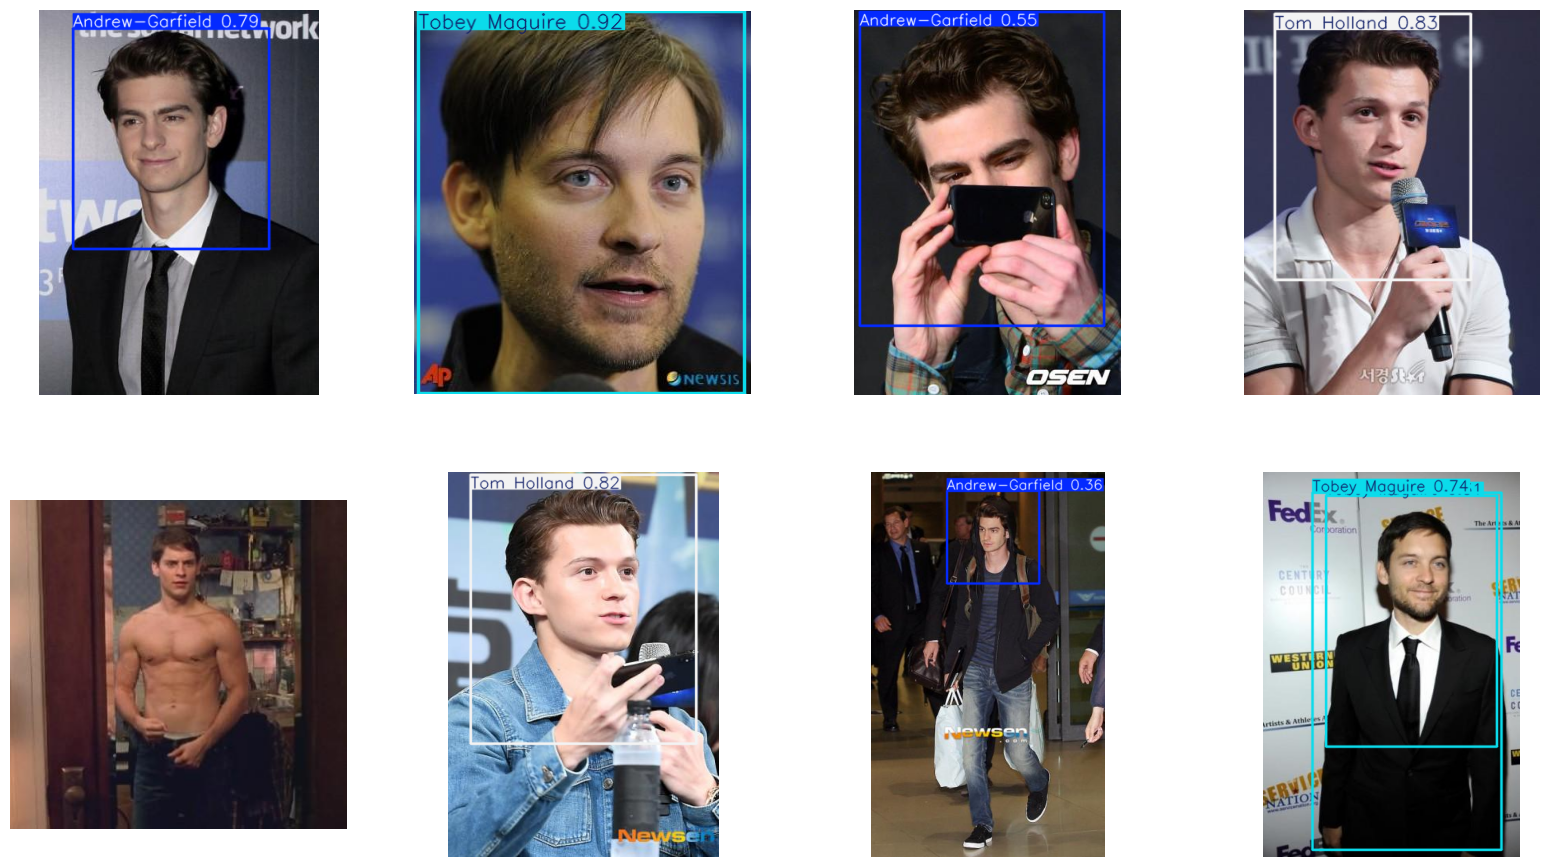

In [28]:
random.seed(42)
test_imgs = sorted(glob.glob(f"{root}/test/images/*"))
pick = random.sample(test_imgs, 8)

fig, axes = plt.subplots(2, 4, figsize=(20, 11))
for ax, p in zip(axes.flatten(), pick):
    r = final.predict(p, conf=0.25, iou=0.7, imgsz=320, verbose=False)[0]
    ax.imshow(cv2.cvtColor(r.plot(), cv2.COLOR_BGR2RGB))
    ax.axis("off")
plt.savefig("test_predictions.png", bbox_inches="tight", dpi=120)
plt.show()

## Step 9 – Where does the model fail?
An image counts as a failure if a true box is missed (no prediction with overlap ≥ 0.5), if the class is wrong, or if the model draws an extra box. Confidence threshold 0.25. This counter is strict on purpose.

16 test images with at least one error
105_jpg.rf.da6e23bfeade7a91e63 ['wrong class: Andrew-Garfield predicted as Tobey Maguire', 'missed Andrew-Garfield', 'wrong class: Andrew-Garfield predicted as Tobey Maguire']
116_jpg.rf.a7f7b199cc84053da96 ['false detection: Tom Holland (0.55)']
117_jpg.rf.41dba38ea0cffc4d60b ['false detection: Tobey Maguire (0.73)']
118_jpg.rf.fc6da6c5fd6d623f483 ['missed Andrew-Garfield', 'false detection: Andrew-Garfield (0.36)']
128_jpg.rf.6274942c9365c0a80f0 ['false detection: Andrew-Garfield (0.30)']
131_jpg.rf.93c9355ee72a8247070 ['wrong class: Andrew-Garfield predicted as Tobey Maguire', 'false detection: Tom Holland (0.27)']
133_jpg.rf.6f6c85ee33402686a66 ['missed Andrew-Garfield', 'false detection: Andrew-Garfield (0.38)']
139_jpg.rf.993311cdedbc1d9bf9d ['false detection: Tom Holland (0.76)']
140_jpg.rf.5d1ccda8a581340b56f ['missed Tobey Maguire']
22_jpg.rf.d872b86f5c0d160efea5 ['missed Andrew-Garfield', 'false detection: Tobey Maguire (0.72)']
29_jpg.r

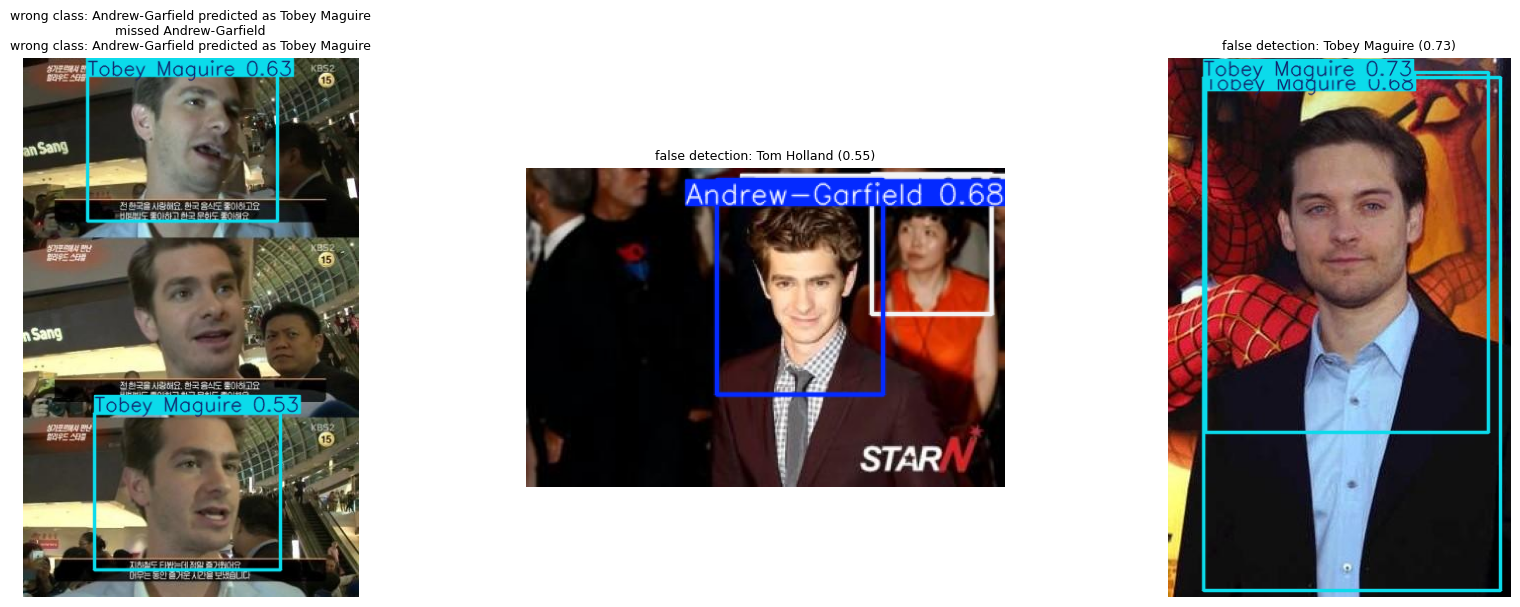

In [30]:
import numpy as np

def iou(a, b):
    ix1, iy1 = max(a[0], b[0]), max(a[1], b[1])
    ix2, iy2 = min(a[2], b[2]), min(a[3], b[3])
    inter = max(0, ix2 - ix1) * max(0, iy2 - iy1)
    union = (a[2]-a[0])*(a[3]-a[1]) + (b[2]-b[0])*(b[3]-b[1]) - inter
    return inter / union if union > 0 else 0

failures = []
for p in sorted(glob.glob(f"{root}/test/images/*")):
    w, h = Image.open(p).size
    stem = os.path.splitext(os.path.basename(p))[0]
    gts = []
    for line in open(f"{root}/test/labels/{stem}.txt").read().strip().splitlines():
        c, x, y, bw, bh = line.split()[:5]
        c = int(c); x, y, bw, bh = float(x)*w, float(y)*h, float(bw)*w, float(bh)*h
        gts.append((c, [x - bw/2, y - bh/2, x + bw/2, y + bh/2]))
    r = final.predict(p, conf=0.25, iou=0.7, imgsz=320, verbose=False)[0]
    preds = [(int(b.cls), b.xyxy[0].tolist(), float(b.conf)) for b in r.boxes]
    used, problems = set(), []
    for c, g in gts:
        best, bi = 0, None
        for i, (pc, pb, pcf) in enumerate(preds):
            v = iou(g, pb)
            if v > best:
                best, bi = v, i
        if bi is None or best < 0.5:
            problems.append(f"missed {names[c]}")
        else:
            used.add(bi)
            if preds[bi][0] != c:
                problems.append(f"wrong class: {names[c]} predicted as {names[preds[bi][0]]}")
    for i, (pc, pb, pcf) in enumerate(preds):
        if i not in used:
            problems.append(f"false detection: {names[pc]} ({pcf:.2f})")
    if problems:
        failures.append((p, problems))

print(len(failures), "test images with at least one error")
for p, pr in failures:
    print(os.path.basename(p)[:30], pr)

if failures:
    n = min(3, len(failures))
    fig, axes = plt.subplots(1, n, figsize=(7 * n, 7))
    axes = np.atleast_1d(axes)
    for ax, (p, pr) in zip(axes, failures[:n]):
        r = final.predict(p, conf=0.25, iou=0.7, imgsz=320, verbose=False)[0]
        ax.imshow(cv2.cvtColor(r.plot(), cv2.COLOR_BGR2RGB))
        ax.axis("off")
        ax.set_title("\n".join(pr), fontsize=9)
    plt.savefig("failure_cases.png", bbox_inches="tight", dpi=120)
    plt.show()

## Step 10 – Save the evidence
Packs learning curves, logs, checkpoints, prediction pictures and split fixes into `evidence.zip` and downloads it.

In [31]:
import shutil
out = "/content/evidence"
shutil.rmtree(out, ignore_errors=True)
for run in ["baseline", "imgsz320"]:
    d = f"{out}/{run}"
    os.makedirs(d)
    for f in ["results.png", "results.csv", "args.yaml", "confusion_matrix.png", "summary.json"]:
        if os.path.exists(f"/content/runs/{run}/{f}"):
            shutil.copy(f"/content/runs/{run}/{f}", d)
    shutil.copy(f"/content/runs/{run}/weights/best.pt", d)
os.makedirs(f"{out}/final_test", exist_ok=True)
for f in glob.glob("/content/runs/final_test/*.png"):
    shutil.copy(f, f"{out}/final_test")
for f in ["ground_truth_examples.png", "split_fixes.txt", "crop_split_fixes.txt",
          "test_predictions.png", "failure_cases.png", "/content/data.yaml"]:
    if os.path.exists(f):
        shutil.copy(f, out)
shutil.make_archive("/content/evidence", "zip", out)

from google.colab import files
files.download("/content/evidence.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Versions used
Printed at the end so they can be written into `requirements.txt`.

In [32]:
import importlib.metadata as md
for pkg in ["ultralytics", "torch", "gdown", "imagehash", "opencv-python", "numpy", "matplotlib", "pillow"]:
    try:
        print(f"{pkg}=={md.version(pkg)}")
    except Exception:
        print(pkg, "not found")

ultralytics==8.4.216
torch==2.14.1+cu130
gdown==5.2.2
imagehash==4.3.2
opencv-python==5.0.0.93
numpy==2.4.6
matplotlib==3.10.0
pillow==11.3.0
